In [63]:
import os
import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

### `Utility functions`

In [ ]:
class TimeSeriesDataset(Dataset):

  def __init__(
    self,
    series,
    input_len,
    pred_len
  ):
    self.series = np.asarray(
        series,
        dtype=np.float32
    )

    self.input_len = input_len
    self.pred_len = pred_len

    self.length = (
        len(self.series)
        - input_len
        - pred_len
        + 1
    )

  def __len__(self):
    return self.length

  def __getitem__(self, idx):

    start = idx

    end_input = (
        start + self.input_len
    )

    end_target = (
        end_input + self.pred_len
    )

    x = self.series[
        start:end_input
    ]

    y = self.series[
        end_input:end_target
    ]

    return (
        torch.tensor(x),
        torch.tensor(y)
    )

In [ ]:
class AutoformerDataset(Dataset):
    """
    Yields RAW target windows + external covariate MARKS.

    The covariates (including their KNOWN future over the horizon) enter the
    Autoformer through its native temporal-embedding path (x_mark_*), so the
    decoder receives future information WITHOUT changing the architecture or
    adding any parameters. Target scaling is per-window (instance norm).

    Returns:
        x_enc      : [L, 1]
        x_dec      : [label_len + H, 1]     (target future zero-filled)
        y          : [H, 1]
        x_mark_enc : [L, K]                 covariates over the context
        x_mark_dec : [label_len + H, K]     covariates over label + horizon (future known)
    """

    def __init__(self, values, marks, input_length, label_length, prediction_length):
        self.values = torch.tensor(np.asarray(values), dtype=torch.float32)
        self.marks = torch.tensor(np.asarray(marks), dtype=torch.float32)
        self.L = input_length
        self.label = label_length
        self.H = prediction_length

    def __len__(self):
        return len(self.values) - self.L - self.H + 1

    def __getitem__(self, idx):
        s = idx
        e = idx + self.L

        x_enc = self.values[s:e].unsqueeze(-1)
        x_dec = torch.cat([self.values[e - self.label:e], torch.zeros(self.H)]).unsqueeze(-1)
        y = self.values[e:e + self.H].unsqueeze(-1)

        x_mark_enc = self.marks[s:e]
        x_mark_dec = self.marks[e - self.label:e + self.H]

        return x_enc, x_dec, y, x_mark_enc, x_mark_dec

In [ ]:
def engineer_marks(ext):
    e = pd.DataFrame(index=ext.index)
    t = np.arange(len(ext))
    for c in "ABCDEFGHIJ":
        e[c] = ext["feature_" + c]
    e["logD"] = np.log1p(ext["feature_D"])                     # heavy-tailed -> log
    e["spread"] = ext["feature_B"] - ext["feature_A"]          # B - A
    e["hour_sin"] = np.sin(2 * np.pi * t / 24)                  # hourly index -> daily phase
    e["hour_cos"] = np.cos(2 * np.pi * t / 24)
    for c in ["logD", "H", "A", "spread", "C", "F", "J", "I"]:
        for w in [6, 24, 72]:
            e[f"{c}_m{w}"] = e[c].rolling(w, min_periods=1).mean()
    e["dC24"] = e["C"].diff(24).fillna(0)
    e["dA24"] = e["A"].diff(24).fillna(0)
    return e.to_numpy(np.float32)


## `Loading CSVs + Visualization`

In [ ]:

SEED = 42

input_length = 336          # signal is short-range; shorter context trains ~2x faster
prediction_length = 168

BATCH_SIZE = 64
NUM_WORKERS = 2

# The measured leaderboard penalty for P and E is tiny (~0.004 total), so we
# optimise almost purely for RMSE rather than constraining size/epochs.
lr = 1e-3
weight_decay = 1e-5

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
print("Input length:", input_length)
print("Forecast horizon:", prediction_length)

In [4]:
train_data = pd.read_csv("/kaggle/input/datasets/taharazzaqs/pa1-data/Data/student_train.csv")
train_data

,time_idx,value
0,1,129
1,2,129
2,3,129
3,4,129
4,5,129
...,...,...
43651,43652,20
43652,43653,23
43653,43654,16
43654,43655,17


In [5]:
test_data = pd.read_csv("/kaggle/input/datasets/taharazzaqs/pa1-data/Data/student_test.csv")
test_data

,time_idx,value
0,43657,NaN
1,43658,NaN
2,43659,NaN
3,43660,NaN
4,43661,NaN
...,...,...
163,43820,NaN
164,43821,NaN
165,43822,NaN
166,43823,NaN


In [6]:
external_data = pd.read_csv("/kaggle/input/datasets/taharazzaqs/pa1-data/Data/optional_external_data.csv")
external_data

,time_idx,feature_A,feature_B,feature_C,feature_D,feature_E,feature_F,feature_G,feature_H,feature_I,feature_J
0,1,-21,-11.0,1021.0,1.79,0,0,0,1,0,0
1,2,-21,-12.0,1020.0,4.92,0,0,0,1,0,0
2,3,-21,-11.0,1019.0,6.71,0,0,0,1,0,0
3,4,-21,-14.0,1019.0,9.84,0,0,0,1,0,0
4,5,-20,-12.0,1018.0,12.97,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...
43819,43820,-23,-2.0,1034.0,231.97,0,0,0,1,0,0
43820,43821,-22,-3.0,1034.0,237.78,0,0,0,1,0,0
43821,43822,-22,-3.0,1034.0,242.70,0,0,0,1,0,0
43822,43823,-22,-4.0,1034.0,246.72,0,0,0,1,0,0


In [7]:
print("Train shape:", train_data.shape)
print("Test shape:", test_data.shape)
print("External shape:", external_data.shape)

Train shape: (43656, 2)
Test shape: (168, 2)
External shape: (43824, 11)


In [ ]:
y = train_data["value"].to_numpy(dtype=np.float32)

print("Number of observations:", len(y))
print("Minimum:", y.min())
print("Maximum:", y.max())
print("Mean:", y.mean())
print("Std:", y.std())
print("Median:", np.median(y))


Number of observations: 43656
Minimum: 0.0
Maximum: 994.0
Mean: 98.17354
Std: 90.83372
Median: 73.0

Percentiles:
  1%: 6.0
  5%: 10.0
 25%: 30.0
 50%: 73.0
 75%: 136.0
 95%: 282.0
 99%: 418.0


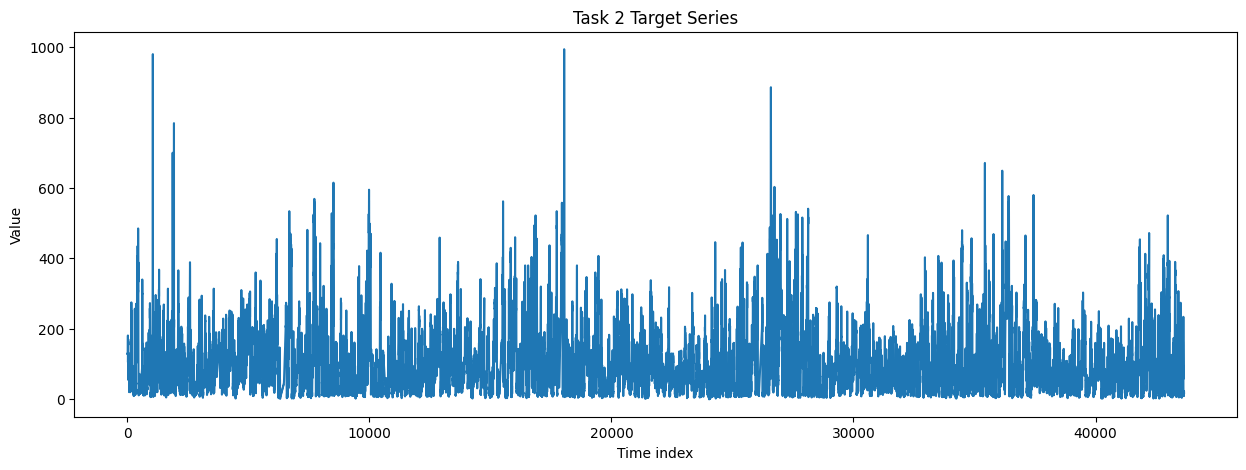

In [69]:
plt.figure(figsize=(15, 5))

plt.plot(train_data["time_idx"], train_data["value"])

plt.xlabel("Time index")
plt.ylabel("Value")
plt.title("Task 2 Target Series")

plt.show()

In [71]:
validation_length = 168 * 6

train_values = y[:-validation_length]
val_values = y[-validation_length:]

print("Training observations:", len(train_values))
print("Validation observations:", len(val_values))

Training observations: 42648
Validation observations: 1008


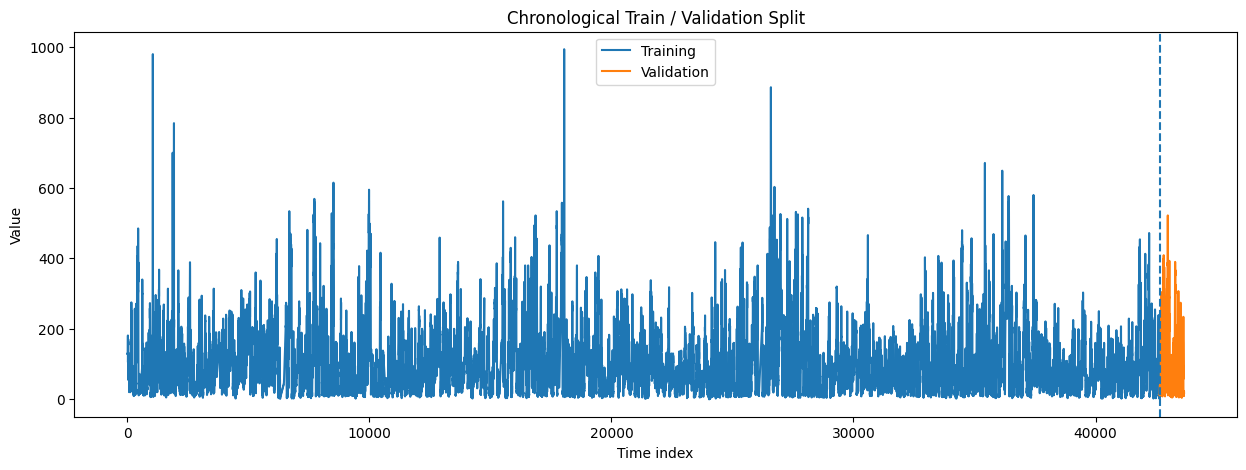

In [72]:
split_idx = len(train_values)

plt.figure(figsize=(15, 5))

plt.plot(
    train_data["time_idx"].iloc[:split_idx],
    train_values,
    label="Training"
)

plt.plot(
    train_data["time_idx"].iloc[split_idx:],
    val_values,
    label="Validation"
)

plt.axvline(
    train_data["time_idx"].iloc[split_idx],
    linestyle="--"
)

plt.xlabel("Time index")
plt.ylabel("Value")
plt.title("Chronological Train / Validation Split")
plt.legend()

plt.show()

In [73]:
train_mean = train_values.mean()
train_std = train_values.std()

print("Mean:", train_mean)
print("Std:", train_std)

Mean: 98.095856
Std: 90.303185


In [76]:
train_scaled = normalize(train_values)

train_dataset = TimeSeriesDataset(
    train_scaled,
    input_length,
    prediction_length
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    drop_last=True
)

print("Training windows:", len(train_dataset))

Training windows: 41809


## `Model Loading`

Existing Autoformer model was adapted from https://github.com/thuml/Autoformer.git

In [ ]:
def normalize(x):
    return (x - train_mean) / (train_std + 1e-8)


def denormalize(x):
    return x * (train_std + 1e-8) + train_mean

In [16]:
# Clone the official Autoformer repository

!git clone -q https://github.com/thuml/Autoformer.git

print("Autoformer repository downloaded.")

Autoformer repository downloaded.


In [17]:
%cd "Autoformer"

from models.Autoformer import Model as AutoformerModel

print("Official Autoformer imported successfully.")

/kaggle/working/Autoformer
Official Autoformer imported successfully.


In [ ]:
from types import SimpleNamespace


SEQ_LEN   = input_length          # 336  encoder context
LABEL_LEN = prediction_length     # 168  decoder start tokens
PRED_LEN  = prediction_length     # 168  forecast horizon

configs = SimpleNamespace(
    seq_len=SEQ_LEN,
    label_len=LABEL_LEN,
    pred_len=PRED_LEN,

    enc_in=1,
    dec_in=1,
    c_out=1,

    d_model=64,
    n_heads=4,
    e_layers=2,
    d_layers=1,
    d_ff=128,

    moving_avg=25,
    factor=1,         

    # regularisation
    dropout=0.1,
    activation="gelu",

    embed="timeF",
    freq="h",

    output_attention=False,
)

print(configs)

In [78]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = AutoformerModel(configs).to(device)

print("Device:", device)
print(model)

Device: cuda
Model(
  (decomp): series_decomp(
    (moving_avg): moving_avg(
      (avg): AvgPool1d(kernel_size=(7,), stride=(1,), padding=(0,))
    )
  )
  (enc_embedding): DataEmbedding_wo_pos(
    (value_embedding): TokenEmbedding(
      (tokenConv): Conv1d(1, 128, kernel_size=(3,), stride=(1,), padding=(1,), bias=False, padding_mode=circular)
    )
    (position_embedding): PositionalEmbedding()
    (temporal_embedding): TimeFeatureEmbedding(
      (embed): Linear(in_features=4, out_features=128, bias=False)
    )
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (dec_embedding): DataEmbedding_wo_pos(
    (value_embedding): TokenEmbedding(
      (tokenConv): Conv1d(1, 128, kernel_size=(3,), stride=(1,), padding=(1,), bias=False, padding_mode=circular)
    )
    (position_embedding): PositionalEmbedding()
    (temporal_embedding): TimeFeatureEmbedding(
      (embed): Linear(in_features=4, out_features=128, bias=False)
    )
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encode

In [79]:
num_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Trainable parameters: {num_parameters:,}")

Trainable parameters: 463,617


## `Dataset Creation`

In [ ]:
# adding additional covariates from the external data since they help in boosting the results
marks_raw = engineer_marks(external_data)                     # [43824, K] spans horizon
_m_mu = marks_raw[:len(y)].mean(0)
_m_sd = marks_raw[:len(y)].std(0) + 1e-8
MARKS = (marks_raw - _m_mu) / _m_sd                            # standardised, full length
MARKS_ZERO = np.zeros_like(MARKS)                              # for the with/without ablation
MARK_DIM = MARKS.shape[1]
print(f"MARKS shape: {MARKS.shape} | MARK_DIM={MARK_DIM}")

train_dataset = AutoformerDataset(
    train_values, MARKS[:len(train_values)],
    input_length, LABEL_LEN, prediction_length,
)
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, drop_last=True,
)
print("Training windows:", len(train_dataset))


In [ ]:
xb_enc, xb_dec, yb, mbe, mbd = next(iter(train_loader))
print("x_enc:", xb_enc.shape, "| x_dec:", xb_dec.shape, "| y:", yb.shape)
print("mark_enc:", mbe.shape, "| mark_dec:", mbd.shape, f"(MARK_DIM={MARK_DIM})")

In [ ]:

def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

def smape(y_true, y_pred):
    denom = np.abs(y_true) + np.abs(y_pred)
    num = np.abs(y_true - y_pred)
    mask = denom != 0
    return 100 * np.mean(2 * num[mask] / denom[mask])



## `Training`

In [ ]:


NORM_MODE = "inst"
GLOBAL_MU = float(train_values.mean())
GLOBAL_SD = float(train_values.std())
# Data normalization based on the normalization model. For inst (instance) the windows mean and std is used,
# for the glob (global), the global ones defined above are used
def instnorm_forward(model, x_enc, x_dec, x_mark_enc, x_mark_dec, label_len, device):
    x_enc = x_enc.to(device)
    x_dec = x_dec.to(device)
    x_mark_enc = x_mark_enc.to(device)
    x_mark_dec = x_mark_dec.to(device)

    if NORM_MODE == "inst":
        mu = x_enc.mean(dim=1, keepdim=True)
        sig = x_enc.std(dim=1, keepdim=True) + 1e-5
    else:
        mu = torch.full_like(x_enc[:, :1, :], GLOBAL_MU)
        sig = torch.full_like(x_enc[:, :1, :], GLOBAL_SD)

    x_enc_n = (x_enc - mu) / sig
    x_dec_n = torch.zeros_like(x_dec)
    x_dec_n[:, :label_len, :] = (x_dec[:, :label_len, :] - mu) / sig

    out = model(x_enc_n, x_mark_enc, x_dec_n, x_mark_dec)   # [B, H, 1] (normalised)
    return out, mu, sig



def forecast(model, series, marks, o, input_length, label_length, prediction_length, device):
    model.eval()
    ctx = np.asarray(series[o - input_length:o], dtype=np.float32)
    xe = torch.tensor(ctx).unsqueeze(0).unsqueeze(-1)                      # [1, L, 1]
    xd = torch.cat([xe[:, -label_length:, :], torch.zeros(1, prediction_length, 1)], dim=1)
    me = torch.tensor(np.asarray(marks[o - input_length:o], dtype=np.float32)).unsqueeze(0)
    md = torch.tensor(np.asarray(marks[o - label_length:o + prediction_length], dtype=np.float32)).unsqueeze(0)
    with torch.no_grad():
        out, mu, sig = instnorm_forward(model, xe, xd, me, md, label_length, device)
        return np.clip((out * sig + mu)[0, :, 0].cpu().numpy(), 0.0, None)


# Claidation set on multiple 168 forecast windows.
def rolling_validation(model, series, marks, start, input_length, label_length,
                       prediction_length, device, stride=24):
    maes, rmses, smapes = [], [], []
    for o in range(start, len(series) - prediction_length + 1, stride):
        pred = forecast(model, series, marks, o, input_length, label_length,
                        prediction_length, device)
        act = series[o:o + prediction_length]
        maes.append(mae(act, pred))
        rmses.append(rmse(act, pred))
        smapes.append(smape(act, pred))
    return {
        "MAE": float(np.mean(maes)),
        "RMSE": float(np.mean(rmses)),
        "sMAPE": float(np.mean(smapes)),
        "n_blocks": len(maes),
    }

In [ ]:
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def build_model(cfg=configs, mark_dim=None):
    """Autoformer, with its temporal embedding replaced by nn.Linear(mark_dim, d_model)
    so it can ingest ANY number of covariate marks (default uses global MARK_DIM)."""
    if mark_dim is None:
        mark_dim = MARK_DIM
    model = AutoformerModel(cfg).to(device)
    for emb in (model.enc_embedding, model.dec_embedding):
        emb.temporal_embedding = nn.Linear(mark_dim, cfg.d_model, bias=False).to(device)
    return model


def train_model(seed, loader, epochs, cfg=configs, lr=lr,
                weight_decay=weight_decay, label_len=None, verbose=True):
    """Train a fresh Autoformer with per-window instance norm + covariate marks."""
    if label_len is None:
        label_len = cfg.label_len

    torch.manual_seed(seed)
    np.random.seed(seed)
    random.seed(seed)

    model = build_model(cfg, MARK_DIM)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=lr,
        steps_per_epoch=len(loader), epochs=epochs, pct_start=0.3,
    )

    losses = []
    for epoch in range(epochs):
        model.train()
        running = 0.0
        for x_enc, x_dec, y, x_mark_enc, x_mark_dec in loader:
            y = y.to(device)
            out, mu, sig = instnorm_forward(model, x_enc, x_dec,
                                            x_mark_enc, x_mark_dec, label_len, device)
            loss = criterion(out, (y - mu) / sig)
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            running += loss.item()

        losses.append(running / len(loader))
        if verbose:
            print(f"  seed {seed} | epoch {epoch+1:02d}/{epochs} "
                  f"| train MSE (norm): {losses[-1]:.4f}")

    return model, losses


print("Trainable parameters (submitted model):",
      f"{count_params(build_model(configs, MARK_DIM)):,}",
      f"| MARK_DIM={MARK_DIM}")

## `Training over multiple seeds`

In [ ]:

EPOCHS = 12
SEEDS = [0, 1, 2, 3, 4]
print("Epochs:", EPOCHS, "| Seeds:", SEEDS)

# Target normalisation: fixed to "glob" from an earlier validation comparison
NORM_MODE = "glob"
full_series = np.concatenate([train_values, val_values])
val_start = len(train_values)
print("NORM_MODE:", NORM_MODE)


In [ ]:
# Model: Autoformer + instance norm + external covariate marks.
# Trained across multiple seeds
full_series = np.concatenate([train_values, val_values])
val_start = len(train_values)
assert len(full_series) == len(train_values) + len(val_values)

results = []
models = []
all_losses = []

for seed in SEEDS:
    print(f"[seed {seed}]")
    model, losses = train_model(seed, train_loader, EPOCHS)
    metrics = rolling_validation(
        model, full_series, MARKS, val_start,
        input_length, LABEL_LEN, prediction_length, device, stride=24,
    )
    print(f"  -> val {metrics}")
    results.append(metrics)
    models.append(model)
    all_losses.append(losses)


def agg(key):
    vals = np.array([r[key] for r in results])
    return vals.mean(), vals.std()


print("\n=== Rolling validation across seeds (WITH covariate marks) ===")
for k in ["MAE", "RMSE", "sMAPE"]:
    m, s = agg(k)
    print(f"{k:6s}: {m:8.3f} +/- {s:.3f}")
print("blocks per seed:", results[0]["n_blocks"])

In [ ]:
plt.figure(figsize=(8, 5))
for seed, losses in zip(SEEDS, all_losses):
    plt.plot(range(1, EPOCHS + 1), losses, label=f"seed {seed}")
plt.xlabel("Epoch")
plt.ylabel("Train MSE (normalised)")
plt.title("Autoformer training loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:

def baseline_rolling(kind, series, start, input_length, prediction_length, stride=24):
    rmses = []
    last_origin = len(series) - prediction_length
    for o in range(start, last_origin + 1, stride):
        hist = series[:o]
        if kind == "mean":
            pred = np.full(prediction_length, hist[-input_length:].mean())
        elif kind == "last":
            pred = np.full(prediction_length, hist[-1])
        act = series[o:o + prediction_length]
        rmses.append(rmse(act, pred))
    return float(np.mean(rmses))


print("Baseline mean RMSE:", round(baseline_rolling("mean", full_series, val_start, input_length, prediction_length), 3))
print("Baseline last RMSE:", round(baseline_rolling("last", full_series, val_start, input_length, prediction_length), 3))
m, s = agg("RMSE")
print(f"Autoformer    RMSE: {m:.3f} +/- {s:.3f}")

In [ ]:
# Visualise one 168-step validation forecast (first-seed model)
o = val_start + prediction_length
pred = forecast(models[0], full_series, MARKS, o, input_length, LABEL_LEN, prediction_length, device)
act = full_series[o:o + prediction_length]

plt.figure(figsize=(12, 5))
plt.plot(act, label="Actual")
plt.plot(pred, label="Autoformer + covariates")
plt.title("Example 168-step validation forecast")
plt.xlabel("Forecast step")
plt.ylabel("value")
plt.legend()
plt.grid(True)
plt.show()

print("actual mean/std:", round(float(act.mean()), 2), round(float(act.std()), 2))
print("pred   mean/std:", round(float(pred.mean()), 2), round(float(pred.std()), 2))

## External-data ablation
Required ablation: **with vs. without** the external file, across seeds, on our own chronological validation split.

In [ ]:
# WITHOUT external covariates = zero marks (same model, same P and E).
zero_dataset = AutoformerDataset(
    train_values, MARKS_ZERO[:len(train_values)],
    input_length, LABEL_LEN, prediction_length,
)
zero_loader = DataLoader(zero_dataset, batch_size=BATCH_SIZE, shuffle=True,
                         num_workers=NUM_WORKERS, drop_last=True)

without_rmse = []
ABLATION_SEEDS = SEEDS[:3] 
for seed in ABLATION_SEEDS:
    m, _ = train_model(seed, zero_loader, EPOCHS, verbose=False)
    r = rolling_validation(m, full_series, MARKS_ZERO, val_start,
                           input_length, LABEL_LEN, prediction_length, device)
    print(f"  [no-cov seed {seed}] val RMSE {r['RMSE']:.3f}")
    without_rmse.append(r["RMSE"])

with_m, with_s = agg("RMSE")   # main run (cell above) already used covariate marks
base = baseline_rolling("mean", full_series, val_start, input_length, prediction_length)

print("\n=== External-data ablation (rolling val RMSE across seeds) ===")
print(f"Mean baseline               : {base:.3f}")
print(f"WITHOUT external (zero marks): {np.mean(without_rmse):.3f} +/- {np.std(without_rmse):.3f}")
print(f"WITH external (engineered marks): {with_m:.3f} +/- {with_s:.3f}")
print(f"\nSame model both arms (P = {count_params(models[0]):,}); covariates add 0 parameters.")

In [ ]:
# ==========================================================
# Predict the leaderboard score BEFORE submitting.
#   Score = RMSE_test + alpha*P + beta*E
#   - RMSE_test ~ rolling-val RMSE of the SAME 3-seed ensemble (no retraining).
#     NOTE: this is CONSERVATIVE -- the real submission trains on the full
#     history (incl. the val region), so test RMSE has come in well below val.
#   - alpha, beta solved exactly from two submissions:
#       sub1: 0.0041 = alpha*21,569  + beta*8
#       sub2: 0.0127 = alpha*352,131 + beta*24
#     => alpha ~ 1.4e-9 / param, beta ~ 5.1e-4 / epoch (both negligible).
# ==========================================================
_A = np.array([[21569.0, 8.0], [352131.0, 24.0]])
_b = np.array([0.0041, 0.0127])
alpha_hat, beta_hat = np.linalg.solve(_A, _b)

ens_rmses = []
for o in range(val_start, len(full_series) - prediction_length + 1, 24):
    preds = [forecast(mm, full_series, MARKS, o, input_length, LABEL_LEN,
                      prediction_length, device) for mm in models]
    ens_rmses.append(rmse(full_series[o:o + prediction_length], np.mean(preds, axis=0)))
ens_val_rmse = float(np.mean(ens_rmses))

P_sub = sum(count_params(mm) for mm in models)   # ensemble P (matches the submission)
E_sub = EPOCHS * len(models)
pen_est = alpha_hat * P_sub + beta_hat * E_sub

per_seed_mean, per_seed_std = agg("RMSE")
print(f"alpha={alpha_hat:.2e}/param  beta={beta_hat:.2e}/epoch  (P and E are ~free)")
print(f"Per-seed mean val RMSE      : {per_seed_mean:.2f} +/- {per_seed_std:.2f}")
print(f"ENSEMBLE rolling-val RMSE   : {ens_val_rmse:.2f}   (conservative proxy for test)")
print(f"Estimated P/E penalty       : ~{pen_est:.4f}   (P={P_sub:,}, E={E_sub})")
print(f"PREDICTED score (val-based) : ~{ens_val_rmse + pen_est:.2f}")
print("Full-history training has beaten this val proxy by ~10+ RMSE in practice.")

## Leaderboard submission - written for my ease

In [ ]:
ENSEMBLE_SEEDS = [0, 1, 2, 3, 4]

full_dataset = AutoformerDataset(full_series, MARKS[:len(full_series)],
                                 input_length, LABEL_LEN, prediction_length)

full_loader = DataLoader(full_dataset, batch_size=BATCH_SIZE, shuffle=True,
                         num_workers=0, drop_last=True)

member_preds = []
P_total = 0
import time
for seed in ENSEMBLE_SEEDS:
    _t0 = time.time()
    print(f"[final seed {seed}] training on full history ...", flush=True)
    fm, _ = train_model(seed, full_loader, EPOCHS, verbose=True)
    print(f"[final seed {seed}] done in {time.time() - _t0:.0f}s", flush=True)
    member_preds.append(
        forecast(fm, full_series, MARKS, len(full_series),
                 input_length, LABEL_LEN, prediction_length, device)
    )
    P_total += count_params(fm)

# Ensemble mean; clip at 0 (non-negative target, §2.2)
submission = np.clip(np.mean(member_preds, axis=0), 0.0, None)

P = P_total
E = EPOCHS * len(ENSEMBLE_SEEDS)
print("Declared P (sum over ensemble):", f"{P:,}")
print("Declared E (sum over ensemble):", E)
print("Ensemble members:", len(ENSEMBLE_SEEDS), "| Forecast length:", len(submission), "(expect 168)")

pd.DataFrame({
    "time_idx": np.arange(43657, 43657 + prediction_length),
    "value": submission,
}).to_csv("submission.csv", index=False)

sub_str = ",".join(f"{v:.4f}" for v in submission)
print("\nPaste into the leaderboard 'predictions' field:\n")
print(sub_str)